<a id="principal-component-analysis-of-county-characteristics"></a>

# Principal component analysis of county characteristics

This section reduces county characteristics into key principal components that capture differences between counties, then looks at how migration patterns differ along these new dimensions.

**Question 7:** Which dimensions summarize county characteristics, and how do migration rates vary along them? **Input:** the validated analysis dataset. **Cohort:** 3,050 eligible counties in 2023. **Purpose:** describe feature variation and subsequent outcome associations.


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/us_migration').is_dir())
sys.path.insert(0, str(ROOT/'src'))
from us_migration.unsupervised import (
    FEATURES, LABELS, MIGRATION, COLORS, STANDARDIZED_FEATURES, STANDARDIZED_MIGRATION, prepare_cross_section,
    configure_plots, save_figure, sample_image, write_json, provenance)
configure_plots()
YEAR, SEED = 2023, 42
INPUT = ROOT/'data/processed/analysis_county_year.parquet'
panel = pd.read_parquet(INPUT)
counties, characteristics, migration = prepare_cross_section(panel, YEAR)
# This is an exploratory fit to all eligible 2023 counties, not a held-out prediction test.
# Source imputation is inherited unchanged; scalers below fit only this cross-section.
X = StandardScaler().fit_transform(characteristics)
M = StandardScaler().fit_transform(migration)
from us_migration.exports import begin_analysis
from us_migration.analysis_exports import export_analysis
BUNDLE = begin_analysis(ROOT, 'pca')
OUT = BUNDLE/'figures'
DOWNLOAD = BUNDLE/'data'
OUT.mkdir(parents=True, exist_ok=True)
DOWNLOAD.mkdir(parents=True, exist_ok=True)
print(f'{YEAR}: {len(counties):,} counties; {int(counties.socioeconomic_imputed.sum())} with imputed predictors; '
      f'{int(counties.net_rate_iqr_flag.sum())} migration outlier flags retained.')
assert not counties.county_fips.duplicated().any()
assert X.shape == (len(counties), 13)
assert np.allclose(X.mean(axis=0), 0, atol=1e-10)
from us_migration.outcomes import OUTCOME_DEFINITIONS, RATE_FIELDS, COUNT_FIELDS, color_limits
from IPython.display import HTML

2023: 3,050 counties; 6 with imputed predictors; 133 migration outlier flags retained.


<a id="overview"></a>

## Overview

Principal component analysis replaces correlated numeric features with orthogonal linear combinations.
For centered standardized matrix **X**, the sample covariance matrix is **S = XᵀX / (n − 1)**.
An eigenvector **v** satisfies **Sv = λv**: it supplies the direction (feature coefficients) of a component,
and its eigenvalue **λ** is the variance of scores **Xv**. Eigenvalues in descending order rank the components;
each divided by their sum gives an explained-variance ratio. Signs of eigenvectors can reverse without changing
the solution. Orthogonal components are uncorrelated in this sample, but are not necessarily independent.

Keeping the leading components reduces dimensionality and reconstruction error for a given linear subspace.
It helps visualize many correlated variables and can reduce redundancy and noise. In high dimensions,
visualization is difficult and distances can become less informative; here 13 features make interpretation,
rather than extreme dimensionality, the main motivation. PCA can also discard low-variance information
relevant to migration.

The first image below shows directions in two-variable cloud using a sample dataset on toys for illustration purposes. The second explains the actual
analysis flow applied to county characteristics data.
References: [PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca),
[feature scaling](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html).

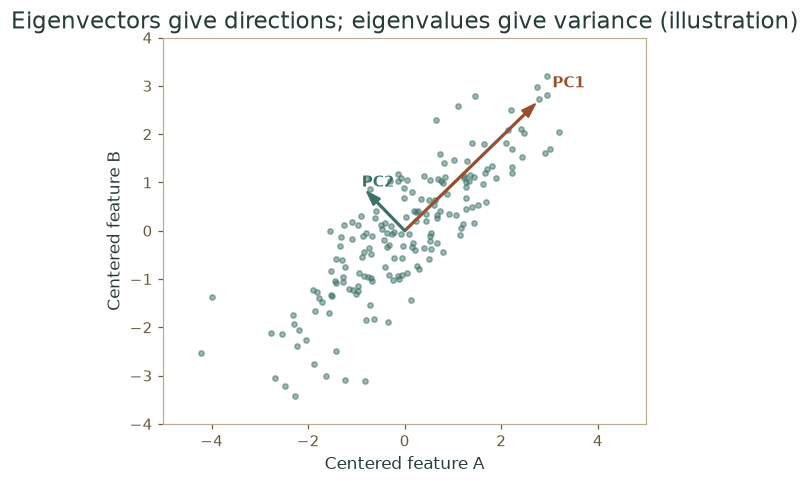

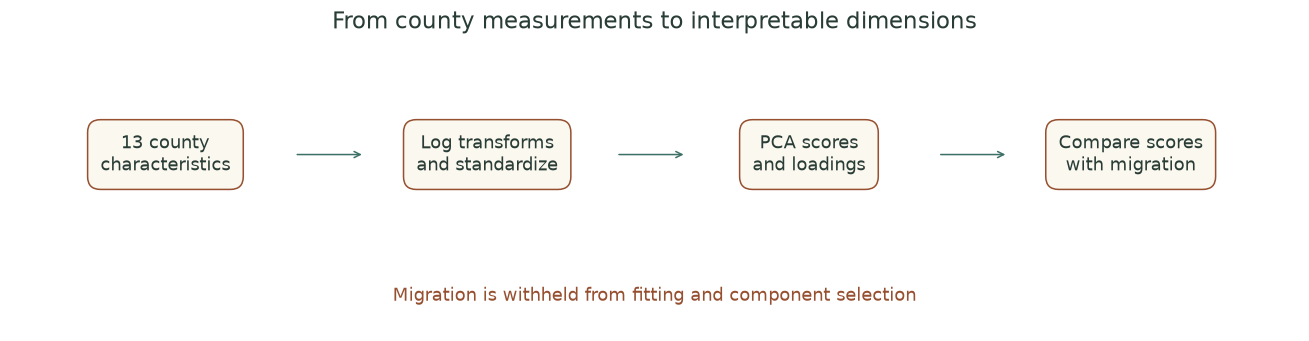

In [2]:
from sklearn.decomposition import PCA
from scipy.stats import spearmanr
rng = np.random.default_rng(SEED)
toy = rng.multivariate_normal([0, 0], [[2, 1.6], [1.6, 2]], size=180)
demo = PCA().fit(toy)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(*toy.T, color=COLORS[1], s=12, alpha=.5)
for i, (direction, variance) in enumerate(zip(demo.components_, demo.explained_variance_)):
    vector = direction * np.sqrt(variance) * 2
    ax.arrow(0, 0, *vector, width=.035, head_width=.2, color=COLORS[i], length_includes_head=True)
    ax.text(*(vector * 1.13), f'PC{i+1}', color=COLORS[i], weight='bold')
ax.set(title='Eigenvectors give directions; eigenvalues give variance (illustration)', xlabel='Centered feature A', ylabel='Centered feature B', xlim=(-5,5), ylim=(-4,4))
ax.set_aspect('equal', adjustable='box'); save_figure(fig, OUT, 'pca-overview-directions.png')
fig, ax = plt.subplots(figsize=(12, 3.2)); ax.axis('off')
steps = ['13 county\ncharacteristics', 'Log transforms\nand standardize', 'PCA scores\nand loadings', 'Compare scores\nwith migration']
for i, label in enumerate(steps):
    x = .12 + .25*i
    ax.text(x, .6, label, ha='center', va='center', fontsize=12, bbox=dict(boxstyle='round,pad=.7', fc='#fbf8f0', ec='#965030'))
    if i < 3: ax.annotate('', xy=(x+.155,.6), xytext=(x+.10,.6), arrowprops=dict(arrowstyle='->',color='#3d7067'))
ax.text(.5, .1, 'Migration is withheld from fitting and component selection', ha='center', fontsize=12, color='#965030')
ax.set_title('From county measurements to interpretable dimensions')
save_figure(fig, OUT, 'pca-overview-workflow.png')

<a id="data-preparation"></a>

## Data preparation

Use the validated `analysis_county_year.parquet` from the data-cleaning notebook, restricted to **2023** and
`geography_level == 'county'`. Alaska and Connecticut state substitutes are excluded, not treated as counties.
Each eligible county has equal weight.

The 13 county characteristics cover population size, age, income, housing, poverty, employment, education,
FEMA incidents, precipitation and temperature. Log10 transforms population, income, home value and rent;
log1p transforms nonnegative incident counts. These transformations reduce long right tails without removing counties.
Z-score each transformed column to mean zero and population standard deviation one. Percentages enter once;
their numerator/denominator counts do not enter again. Correlated housing/economic variables can still give that
domain more influence, so the resulting profiles depend on this feature specification.

**Inputs contain only numeric measurements, with no outcome labels.** County IDs/names, year,
imputation flags, existing migration categories and migration outcomes stay outside the characteristic matrix.
Keep row keys separately for interpretation. Existing imputation remains documented; no new missing values
are filled. Ordinary outliers are retained, so inspect small clusters before interpreting them.
Temperature and precipitation are annual conditions, not long-run climate normals; incidents measure FEMA
declarations, not total hazard exposure. Monetary values are not local cost-of-living adjusted.


PCA requires finite numeric observations with comparable scaling. The current PCA is unweighted and
linear; it is not appropriate to place county FIPS codes or categorical band codes on numeric axes.
StandardScaler handles scale before PCA centers its input. Component variance is preserved for interpreting the dimensions.
Standardized values are dimensionless z-scores. After scaling, sample DataFrames, CSVs and published snapshots use unit-free names: `temperature`, `precipitation`, `poverty`, `inflow` and `outflow`. Original-unit source and outcome columns retain their definitions. Z-scoring changes mean and scale; it does not impose a normal distribution.


,log10_population,median_age,log10_income,log10_home_value,log10_rent,poverty_pct,unemployment_pct,vacancy_pct,homeownership_pct,bachelors_plus_pct,log1p_incidents,precipitation_inches,temperature_f
0,4.773,39.2,4.844,5.296,3.079,10.684,2.542,8.928,74.910,28.283,0.693,49.81,66.292
1,5.380,43.7,4.875,5.458,3.083,10.515,3.194,26.359,77.535,32.798,0.000,49.37,69.883
2,4.394,40.7,4.646,5.041,2.809,21.921,5.709,22.406,67.489,11.465,0.693,49.11,66.692
3,4.345,41.3,4.709,5.123,2.904,20.512,9.984,16.711,77.176,11.468,0.000,46.88,64.667
4,4.773,40.9,4.786,5.230,2.871,14.095,5.835,11.358,79.506,15.579,0.000,53.83,63.208


,log10_population,median_age,log10_income,log10_home_value,log10_rent,poverty,unemployment,vacancy,homeownership,bachelors_plus,log1p_incidents,precipitation,temperature
0,0.450,-0.473,0.358,0.143,1.039,-0.613,-0.954,-0.766,0.210,0.420,1.492,0.981,1.155
1,1.421,0.383,0.645,0.894,1.072,-0.642,-0.672,0.996,0.525,0.864,-0.575,0.947,1.586
2,-0.156,-0.188,-1.469,-1.045,-1.192,1.281,0.415,0.597,-0.680,-1.234,1.492,0.928,1.203
3,-0.233,-0.074,-0.886,-0.666,-0.406,1.044,2.263,0.021,0.481,-1.234,-0.575,0.759,0.961
4,0.450,-0.150,-0.178,-0.167,-0.680,-0.038,0.470,-0.520,0.761,-0.829,-0.575,1.285,0.786


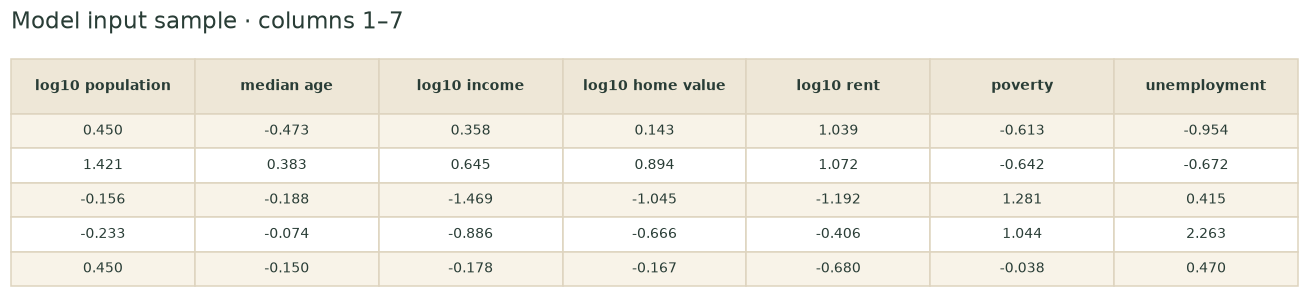

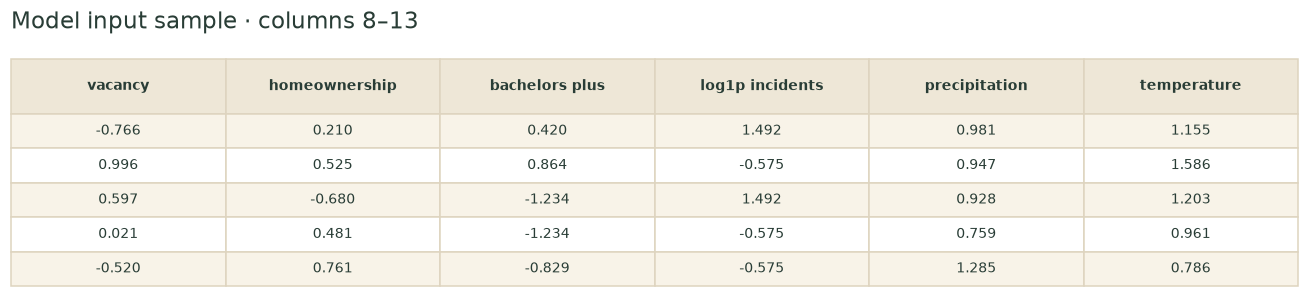

In [3]:
display(characteristics.head().round(3))
standardized = pd.DataFrame(X, columns=STANDARDIZED_FEATURES)
display(standardized.head().round(3))
standardized.head(20).to_csv(DOWNLOAD/'pca-standardized-sample.csv', index=False)
for start, stop, suffix in [(0, 7, 'a'), (7, 13, 'b')]:
    sample_image(standardized.iloc[:5, start:stop], OUT, f'pca-sample-{suffix}.png',
                 f'Model input sample · columns {start+1}–{stop}')
counties[['county_fips', 'county_name', 'year']].head(20).to_csv(DOWNLOAD/'sample-row-keys.csv', index=False)

<a id="fit-pca-and-choose-dimensionality"></a>

## Fit PCA and choose dimensionality

Fit all 13 components with the full SVD solver. Retain the smallest number reaching **80% cumulative
explained feature variance**, a declared compression target, and report the 90% alternative as sensitivity.
Use a two-component projection for visualization even if the retained analysis requires more components.
This rule uses no migration information.

,component,eigenvalue,variance_ratio,cumulative
0,PC1,4.4488,0.3421,0.3421
1,PC2,2.6428,0.2032,0.5453
2,PC3,1.4722,0.1132,0.6585
3,PC4,1.0171,0.0782,0.7368
4,PC5,0.9114,0.0701,0.8068
5,PC6,0.6106,0.0470,0.8538
6,PC7,0.5734,0.0441,0.8979
7,PC8,0.3548,0.0273,0.9252
8,PC9,0.2801,0.0215,0.9467
9,PC10,0.2535,0.0195,0.9662


5 components retain 80.7%; 8 reach 90%.


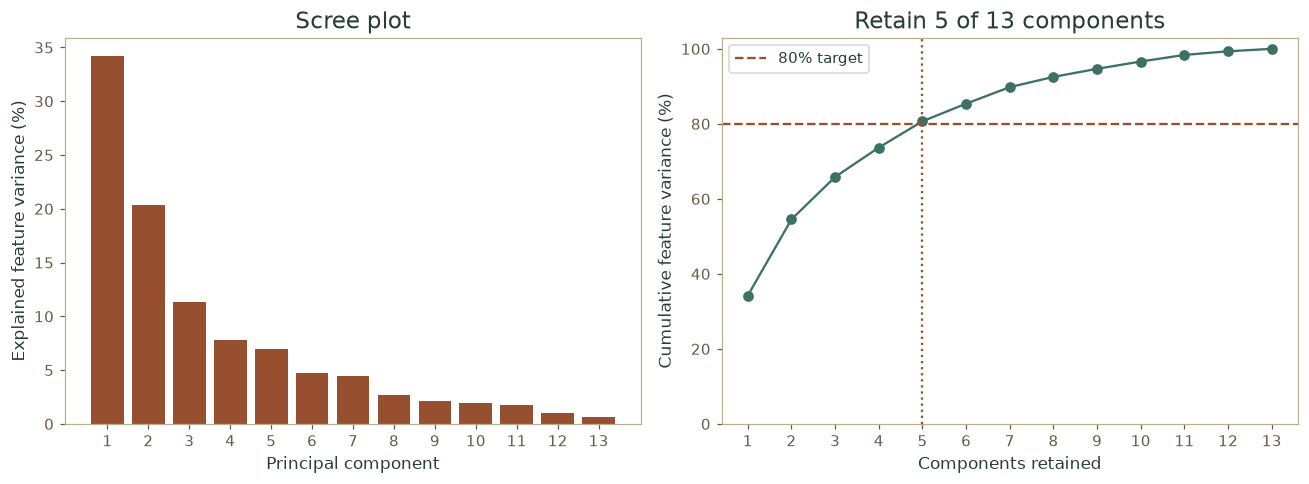

In [4]:
with threadpool_limits(limits=1):
    model = PCA(svd_solver='full', whiten=False).fit(X)
    scores = model.transform(X)
ratio = model.explained_variance_ratio_
cumulative = np.cumsum(ratio)
retained = int(np.searchsorted(cumulative, .80) + 1)
retained90 = int(np.searchsorted(cumulative, .90) + 1)
pcs = [f'PC{i+1}' for i in range(X.shape[1])]
covariance = np.cov(X, rowvar=False)
assert np.allclose(covariance @ model.components_.T,
                   model.components_.T * model.explained_variance_, atol=1e-8)
assert np.allclose(model.components_ @ model.components_.T, np.eye(len(pcs)), atol=1e-10)
assert np.allclose(model.inverse_transform(scores), X, atol=1e-10)
variance = pd.DataFrame({'component': pcs, 'eigenvalue': model.explained_variance_,
                        'variance_ratio': ratio, 'cumulative': cumulative})
display(variance.round(4))
print(f'{retained} components retain {cumulative[retained-1]:.1%}; {retained90} reach 90%.')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(range(1,14), ratio * 100, color=COLORS[0]); axes[0].set(title='Scree plot', xlabel='Principal component', ylabel='Explained feature variance (%)', xticks=range(1,14))
axes[1].plot(range(1,14), cumulative * 100, 'o-', color=COLORS[1])
axes[1].axhline(80, ls='--', color=COLORS[0], label='80% target')
axes[1].axvline(retained, ls=':', color=COLORS[0]); axes[1].legend()
axes[1].set(title=f'Retain {retained} of 13 components', xlabel='Components retained', ylabel='Cumulative feature variance (%)', xticks=range(1,14), ylim=(0,103))
save_figure(fig, OUT, 'pca-variance.png')
variance.to_csv(DOWNLOAD/'pca-variance.csv', index=False)

<a id="results"></a>

## Results

<a id="Loadings"></a>
<a id="loadings-eigenvector-coefficients"></a>

### Loadings: eigenvector coefficients

Here, **loadings** means the eigenvector coefficients in the PC1–PC5 table. Each county score is a weighted sum of its centered, standardized characteristics: $t_{ik}=\sum_j (x_{ij}-\bar{x}_j)v_{jk}$. A positive weight adds to the score when a county is above the cohort mean on that characteristic; a negative weight subtracts from it. The term “loadings” also commonly refers to coefficients scaled by the square root of the eigenvalue. The next section labels variable–score correlations explicitly to distinguish the two quantities.

In [5]:
coefficients = pd.DataFrame(model.components_.T, index=FEATURES, columns=pcs)
loadings = coefficients.mul(np.sqrt(model.explained_variance_), axis=1).div(X.std(axis=0, ddof=1), axis=0)
assert np.allclose(loadings.to_numpy(), np.corrcoef(X.T, scores.T)[:13,13:], atol=1e-8)
display(coefficients.iloc[:, :retained].round(3))


,PC1,PC2,PC3,PC4,PC5
log10_population,0.324,-0.322,0.112,-0.030,-0.080
median_age,-0.114,0.365,0.496,0.119,-0.154
log10_income,0.426,0.169,0.022,-0.093,-0.010
log10_home_value,0.418,0.019,0.168,0.215,-0.021
log10_rent,0.414,-0.127,0.165,0.103,-0.093
poverty_pct,-0.322,-0.357,-0.033,0.227,0.013
unemployment_pct,-0.148,-0.347,0.176,0.433,-0.175
vacancy_pct,-0.237,0.215,0.313,0.488,-0.100
homeownership_pct,-0.084,0.450,0.275,-0.311,-0.079
bachelors_plus_pct,0.393,-0.003,0.058,0.275,-0.017


<a id="variable-score-correlations"></a>

### Variable–score correlations

The table and heatmap show Pearson correlations between each standardized characteristic and each retained component score. Absolute values closer to 1 indicate stronger alignment, while values near 0 indicate weak linear alignment. Positive and negative signs identify characteristics that rise and fall with the score. Component signs can reverse together with all their coefficients and correlations.

For eigenvector coefficient $v_{jk}$, eigenvalue $\lambda_k$, and the sample standard deviation $s_j$ of standardized feature $j$, $\operatorname{Corr}(X_j,t_k)=v_{jk}\sqrt{\lambda_k}/s_j$. This analysis standardizes with population standard deviations, so the small sample-standard-deviation adjustment is included explicitly. Scaled coefficients coincide with these correlations when the inputs have unit sample variance.

,PC1,PC2,PC3,PC4,PC5
log10_population,0.683,-0.523,0.136,-0.030,-0.076
median_age,-0.241,0.594,0.601,0.120,-0.147
log10_income,0.899,0.274,0.026,-0.093,-0.009
log10_home_value,0.882,0.032,0.203,0.217,-0.020
log10_rent,0.873,-0.207,0.200,0.104,-0.089
poverty_pct,-0.679,-0.581,-0.040,0.229,0.013
unemployment_pct,-0.312,-0.563,0.213,0.436,-0.167
vacancy_pct,-0.500,0.350,0.380,0.492,-0.095
homeownership_pct,-0.178,0.732,0.334,-0.314,-0.075
bachelors_plus_pct,0.830,-0.005,0.070,0.277,-0.016


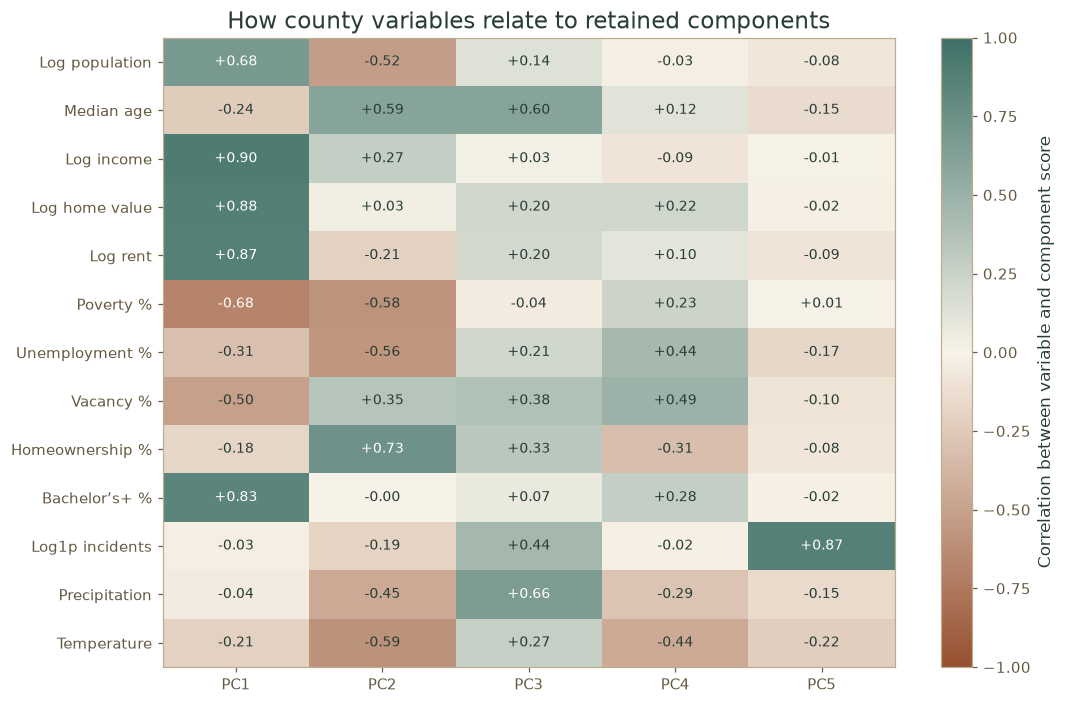

In [6]:
display(loadings.iloc[:, :retained].round(3))
coefficients.to_csv(DOWNLOAD/'pca-coefficients.csv')
loadings.to_csv(DOWNLOAD/'pca-variable-correlations.csv')
fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(loadings.iloc[:, :retained], cmap='migration_diverging', vmin=-1, vmax=1, aspect='auto')
for i in range(13):
    for j in range(retained):
        v = loadings.iloc[i,j]
        ax.text(j,i,f'{v:+.2f}',ha='center',va='center',fontsize=9,color='white' if abs(v)>.65 else '#293d36')
ax.set(xticks=range(retained), xticklabels=pcs[:retained], yticks=range(13), yticklabels=LABELS,
       title='How county variables relate to retained components')
fig.colorbar(im, ax=ax, label='Correlation between variable and component score')
save_figure(fig, OUT, 'pca-loadings.png')

<a id="interpretation-of-pc1-pc5"></a>

### Interpretation of PC1–PC5

Each entry combines explained feature variance, the strongest positive and negative variable–score correlations, and the meaning of higher and lower scores. Labels summarize overlapping county characteristics; small correlations indicate weak parts of a contrast.

In [7]:
plain_readings = [('Income, education and housing costs', 'Higher scores describe counties with higher incomes, home values, rents and educational attainment, often with larger populations and less poverty. In everyday terms, this is an affluence and housing-cost dimension.'), ('Older, owner-occupied communities in cooler climates', 'Higher scores describe older populations and more homeownership, alongside cooler temperatures, smaller populations, less poverty and less unemployment. This combines settled household patterns with climate and economic differences.'), ('Wetter, older communities with more recorded incidents', 'Higher scores describe wetter counties with older populations and more FEMA-recorded incidents, alongside more housing vacancy. This is a combined age, rainfall and incident-history dimension.'), ('Housing vacancy and unemployment in cooler climates', 'Higher scores describe more vacant housing and unemployment, together with cooler temperatures and less homeownership. This captures a housing and labor-market contrast with a climate element.'), ('Recorded disaster-incident history', 'Higher scores chiefly describe more distinct FEMA-recorded incidents; cooler temperatures and lower unemployment have much smaller contributions. This largely isolates incident history after the earlier components capture other shared patterns.')]

lower_readings = [
    'Lower scores describe lower incomes, housing costs and educational attainment, with more poverty.',
    'Lower scores describe younger populations, less homeownership and warmer climates, with larger populations and more poverty and unemployment.',
    'Lower scores describe drier counties, younger populations and fewer recorded incidents, with less housing vacancy.',
    'Lower scores describe less vacancy and unemployment, warmer temperatures and more homeownership.',
    'Lower scores chiefly describe fewer recorded incidents; temperature and unemployment provide weaker contrasts.'
]
interpretations = []
for i, (title, higher) in enumerate(plain_readings):
    pc = pcs[i]
    values = loadings[pc]
    def describe(series):
        return ', '.join(f'{LABELS[FEATURES.index(f)]} ({v:+.3f})' for f,v in series.items())
    positive = describe(values[values > 0].nlargest(3))
    negative = describe(values[values < 0].nsmallest(3))
    reading = higher + ' ' + lower_readings[i]
    interpretations.append(dict(component=pc, title=title, variance_ratio=float(ratio[i]),
        positive=positive, negative=negative, interpretation=reading,
        features=describe(values.loc[values.abs().nlargest(3).index])))
    display(Markdown(f'**{pc} — {title} ({ratio[i]:.1%} of feature variance).** '
        f'Strongest positive correlations: {positive}. Strongest negative correlations: {negative}. '
        f'{reading}'))


**PC1 — Income, education and housing costs (34.2% of feature variance).** Strongest positive correlations: Log income (+0.899), Log home value (+0.882), Log rent (+0.873). Strongest negative correlations: Poverty % (-0.679), Vacancy % (-0.500), Unemployment % (-0.312). Higher scores describe counties with higher incomes, home values, rents and educational attainment, often with larger populations and less poverty. In everyday terms, this is an affluence and housing-cost dimension. Lower scores describe lower incomes, housing costs and educational attainment, with more poverty.

**PC2 — Older, owner-occupied communities in cooler climates (20.3% of feature variance).** Strongest positive correlations: Homeownership % (+0.732), Median age (+0.594), Vacancy % (+0.350). Strongest negative correlations: Temperature (-0.589), Poverty % (-0.581), Unemployment % (-0.563). Higher scores describe older populations and more homeownership, alongside cooler temperatures, smaller populations, less poverty and less unemployment. This combines settled household patterns with climate and economic differences. Lower scores describe younger populations, less homeownership and warmer climates, with larger populations and more poverty and unemployment.

**PC3 — Wetter, older communities with more recorded incidents (11.3% of feature variance).** Strongest positive correlations: Precipitation (+0.662), Median age (+0.601), Log1p incidents (+0.438). Strongest negative correlations: Poverty % (-0.040). Higher scores describe wetter counties with older populations and more FEMA-recorded incidents, alongside more housing vacancy. This is a combined age, rainfall and incident-history dimension. Lower scores describe drier counties, younger populations and fewer recorded incidents, with less housing vacancy.

**PC4 — Housing vacancy and unemployment in cooler climates (7.8% of feature variance).** Strongest positive correlations: Vacancy % (+0.492), Unemployment % (+0.436), Bachelor’s+ % (+0.277). Strongest negative correlations: Temperature (-0.439), Homeownership % (-0.314), Precipitation (-0.287). Higher scores describe more vacant housing and unemployment, together with cooler temperatures and less homeownership. This captures a housing and labor-market contrast with a climate element. Lower scores describe less vacancy and unemployment, warmer temperatures and more homeownership.

**PC5 — Recorded disaster-incident history (7.0% of feature variance).** Strongest positive correlations: Log1p incidents (+0.871), Poverty % (+0.013). Strongest negative correlations: Temperature (-0.225), Unemployment % (-0.167), Precipitation (-0.155). Higher scores chiefly describe more distinct FEMA-recorded incidents; cooler temperatures and lower unemployment have much smaller contributions. This largely isolates incident history after the earlier components capture other shared patterns. Lower scores chiefly describe fewer recorded incidents; temperature and unemployment provide weaker contrasts.

<a id="Migration-along-continuous-dimensions"></a>
<a id="variation-in-migration-outcomes-along-the-principal-components"></a>

### Variation in migration outcomes along the principal components

The PC1–PC2 score maps provide an overview of county positions, colored separately by net migration, inflow and outflow rates. All three rates use IRS individuals per 1,000 ACS residents. The coordinates summarize county characteristics, with migration added afterward. PC1–PC5 then anchor the component–outcome correlations and score-quintile comparisons.

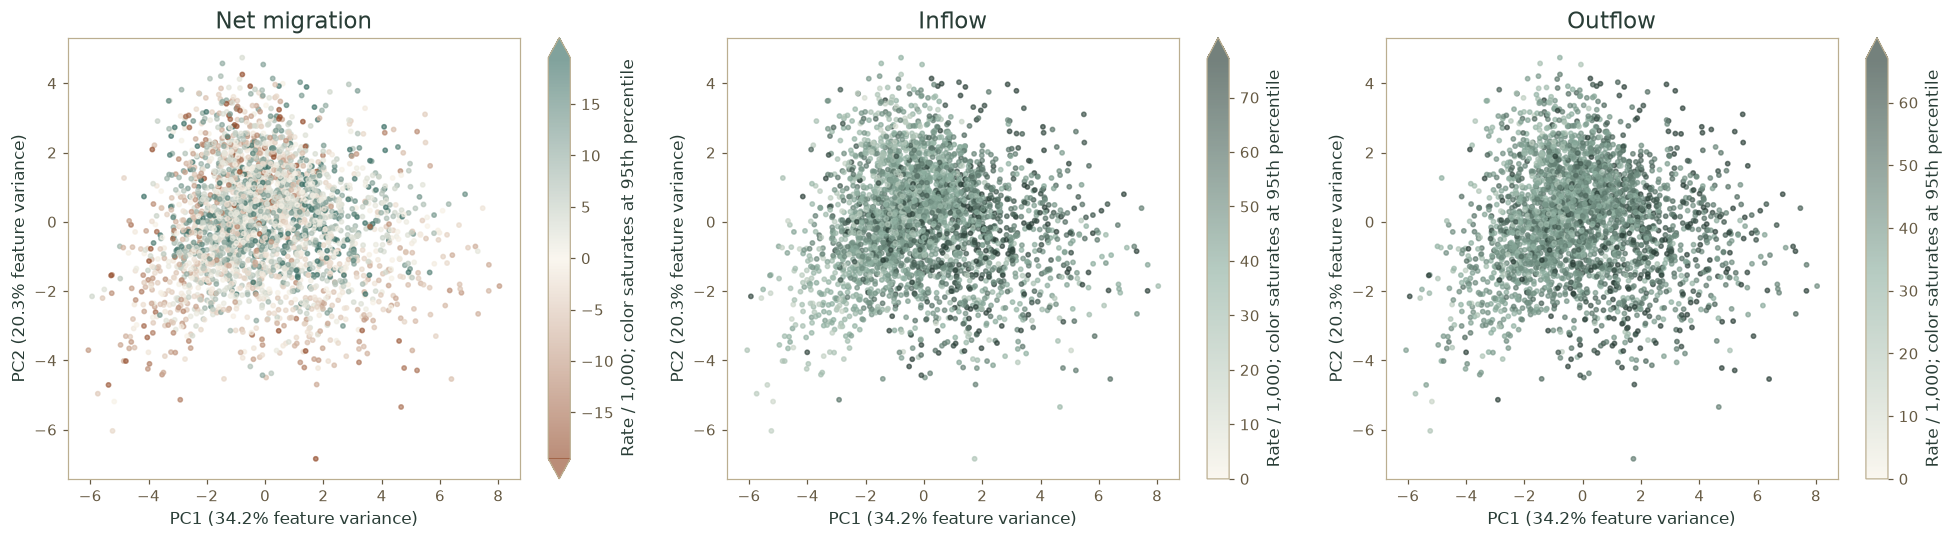

**Component–outcome correlations: PC1–PC5.** Spearman rho summarizes monotonic association: positive values accompany higher rates, negative values lower rates, and larger absolute values stronger rank association.

outcome,net,inflow,outflow
component,,,
PC1,0.083,0.309,0.335
PC2,0.095,-0.025,-0.065
PC3,0.362,0.219,0.033
PC4,-0.236,-0.121,-0.023
PC5,-0.159,-0.163,-0.103


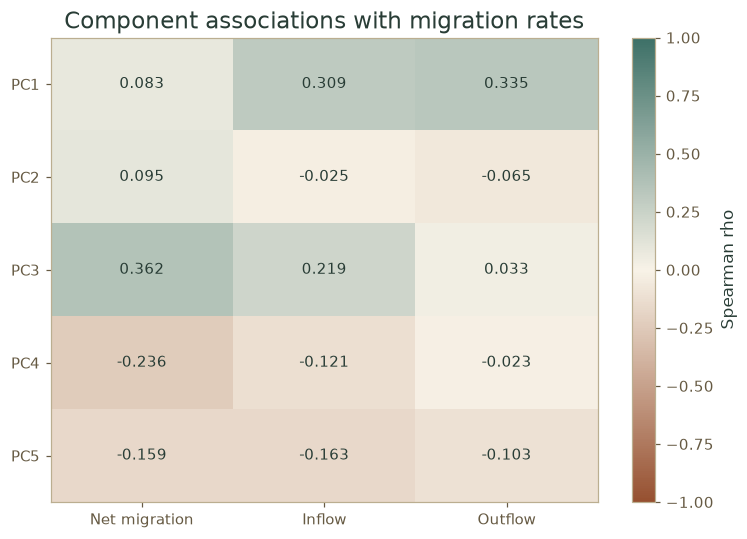

**Score quintiles: PC1–PC5.** Within each component, five roughly equal-sized county groups run from lower to higher scores. Points show median rates; bars span the middle 50% of county rates. The three outcomes share county rows and population denominators.

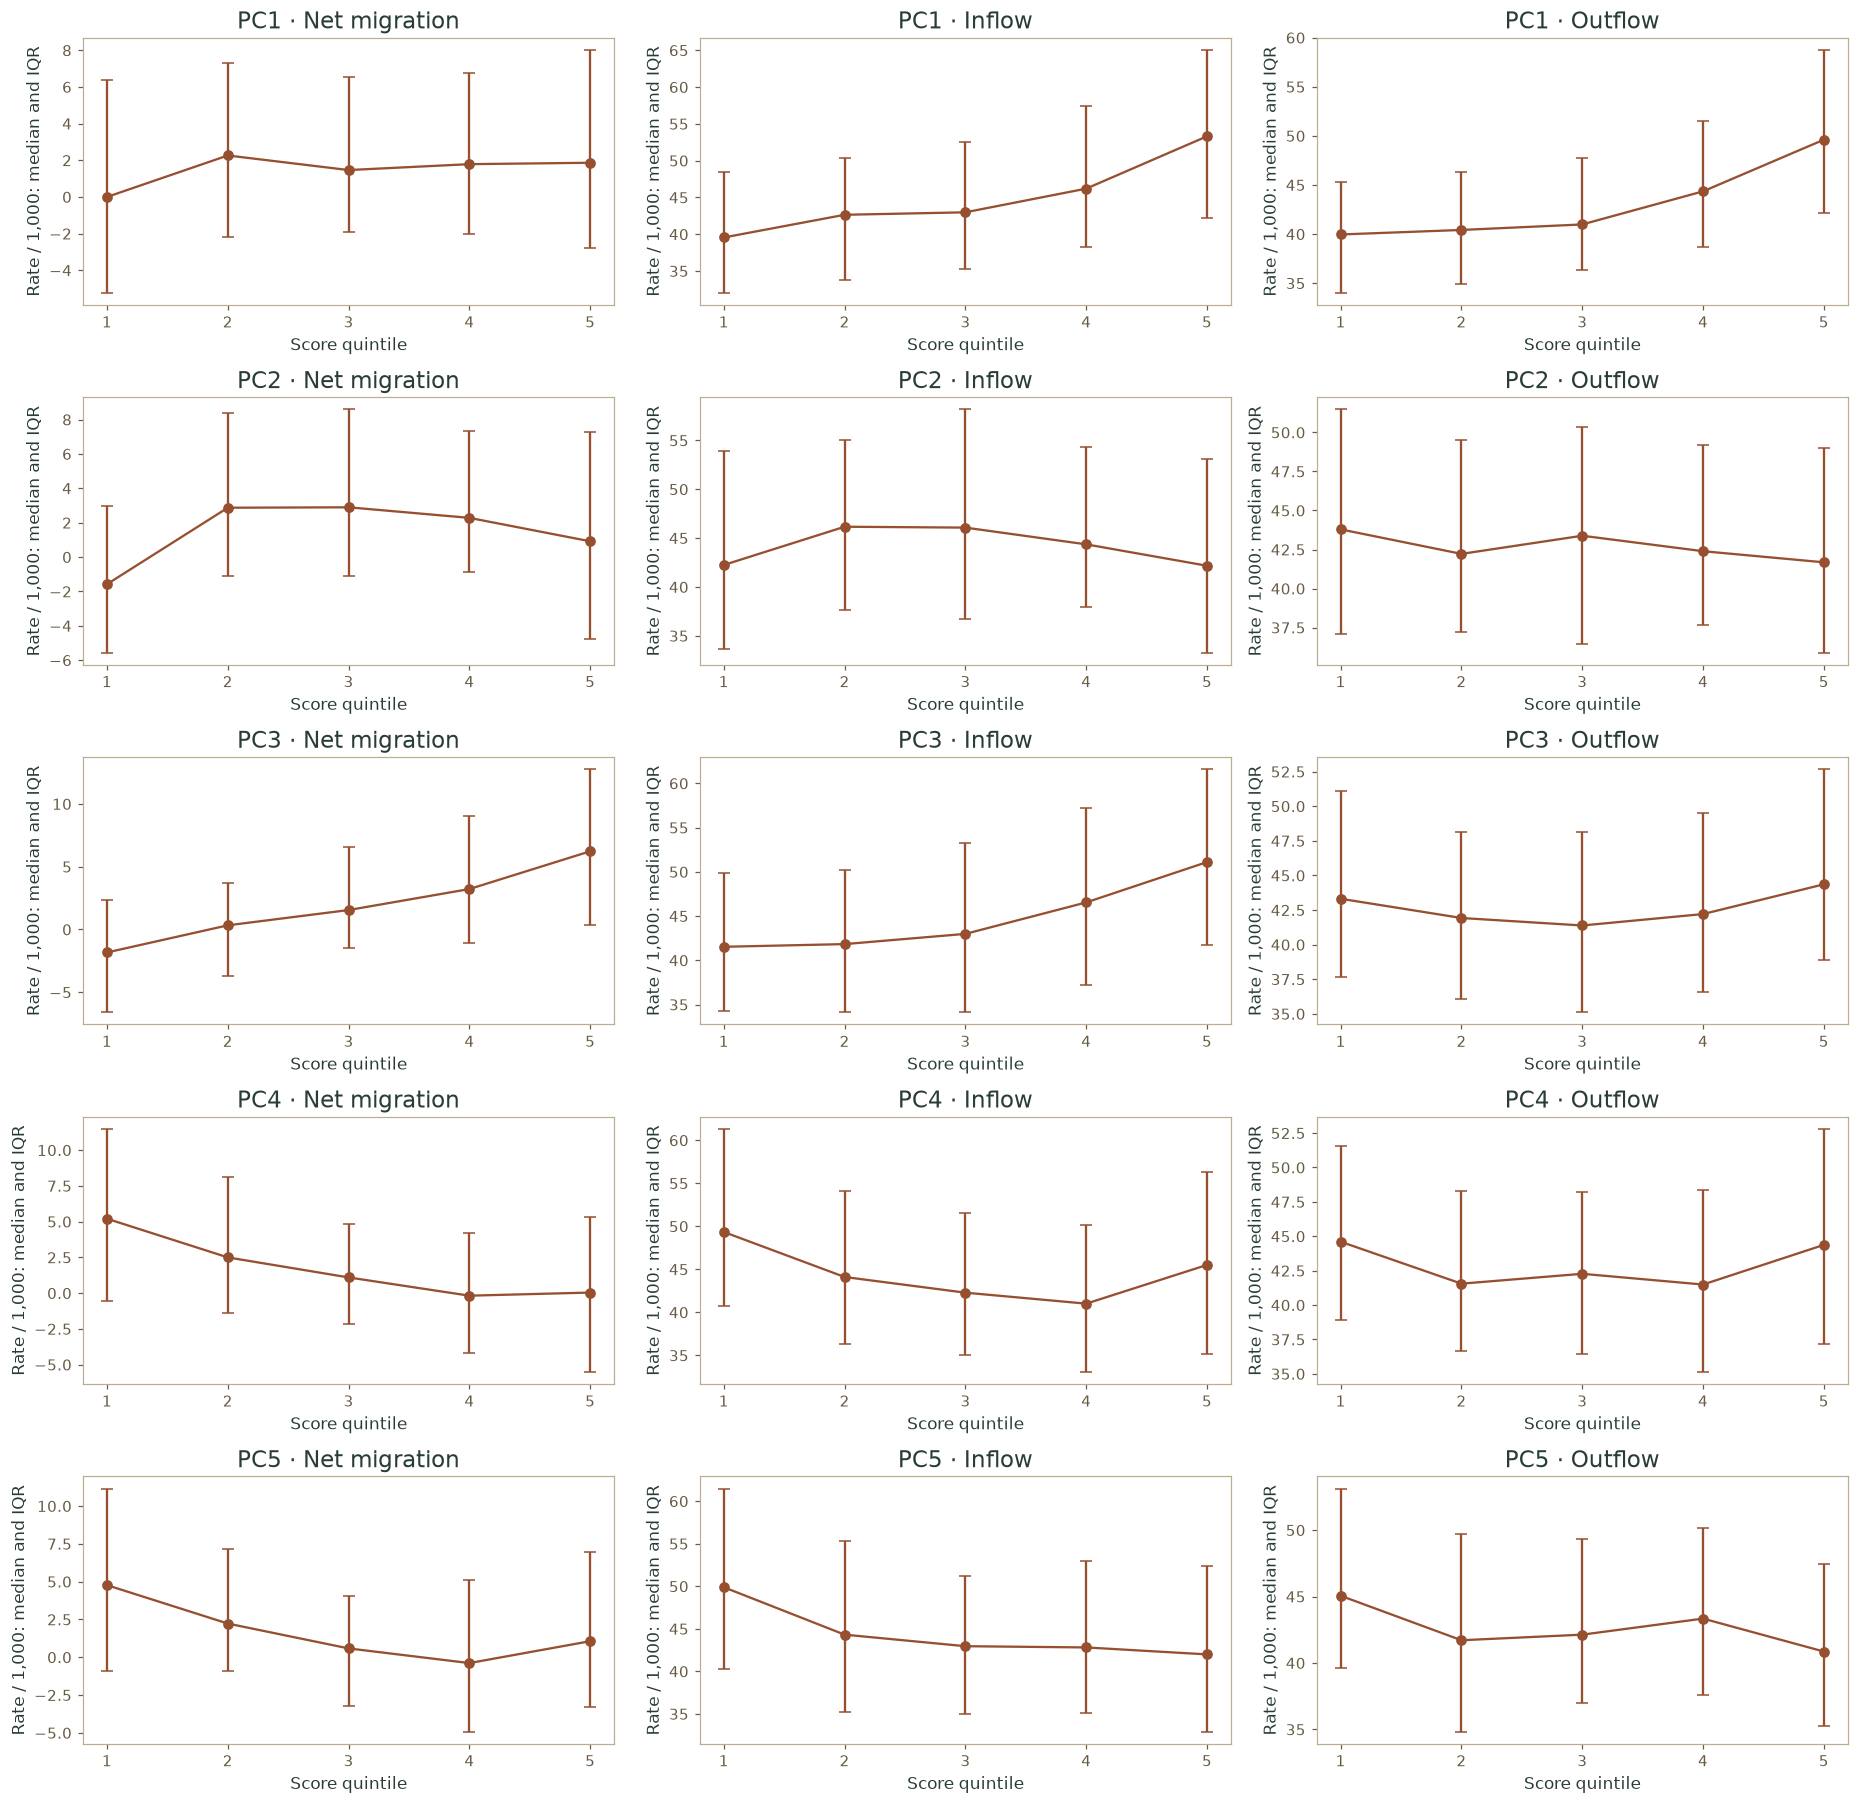

In [8]:
associations = pd.DataFrame([dict(component=pc, outcome=o['id'],
    spearman_rho=float(spearmanr(scores[:,i], counties[o['rate']]).statistic), retained=i<retained)
    for i,pc in enumerate(pcs) for o in OUTCOME_DEFINITIONS])

score_table = counties[['county_fips','county_name','year','population']+COUNT_FIELDS+RATE_FIELDS].copy()
score_table[pcs] = scores
score_table.to_csv(DOWNLOAD/'pca-county-scores.csv', index=False)
associations.to_csv(DOWNLOAD/'pca-migration-associations.csv',index=False)
limits = color_limits(counties)
fig, axes = plt.subplots(1,3,figsize=(18,5))
for o,ax in zip(OUTCOME_DEFINITIONS,axes):
    lim=limits[o['id']]
    im=ax.scatter(scores[:,0],scores[:,1],c=counties[o['rate']],cmap='migration_diverging' if o['id']=='net' else 'migration_sequential',
                  vmin=-lim if o['id']=='net' else 0,vmax=lim,s=8,alpha=.65)
    ax.set(title=o['label'],xlabel=f'PC1 ({ratio[0]:.1%} feature variance)',ylabel=f'PC2 ({ratio[1]:.1%} feature variance)')
    fig.colorbar(im,ax=ax,label='Rate / 1,000; color saturates at 95th percentile',extend='both' if o['id']=='net' else 'max')
save_figure(fig,OUT,'pca-scores.png')
display(Markdown('**Component–outcome correlations: PC1–PC5.** Spearman rho summarizes monotonic association: positive values accompany higher rates, negative values lower rates, and larger absolute values stronger rank association.'))
display(associations.loc[associations.retained].pivot(index='component',columns='outcome',values='spearman_rho').reindex(columns=[o['id'] for o in OUTCOME_DEFINITIONS]).round(3))
matrix=associations.pivot(index='component',columns='outcome',values='spearman_rho').loc[pcs[:retained],[o['id'] for o in OUTCOME_DEFINITIONS]]
fig,ax=plt.subplots(figsize=(7,5))
im=ax.imshow(matrix,vmin=-1,vmax=1,cmap='migration_diverging',aspect='auto')
ax.set(xticks=range(3),xticklabels=[o['label'] for o in OUTCOME_DEFINITIONS],yticks=range(retained),yticklabels=pcs[:retained],title='Component associations with migration rates')
for i in range(retained):
    for j in range(3):ax.text(j,i,f'{matrix.iloc[i,j]:.3f}',ha='center',va='center')
fig.colorbar(im,ax=ax,label='Spearman rho')
save_figure(fig,OUT,'pca-associations.png')
display(Markdown('**Score quintiles: PC1–PC5.** Within each component, five roughly equal-sized county groups run from lower to higher scores. Points show median rates; bars span the middle 50% of county rates. The three outcomes share county rows and population denominators.'))
fig,axes=plt.subplots(retained,3,figsize=(17,3.3*retained),squeeze=False)
quintile_rows=[]
for i in range(retained):
    bands=pd.qcut(scores[:,i],5,labels=False)
    for j,o in enumerate(OUTCOME_DEFINITIONS):
        for band in range(5):
            values=counties.loc[bands==band,o['rate']]
            quintile_rows.append(dict(component=pcs[i],outcome=o['id'],quintile=band+1,counties=len(values),
                median=float(values.median()),q25=float(values.quantile(.25)),q75=float(values.quantile(.75))))
        g=pd.DataFrame(quintile_rows[-5:]);ax=axes[i,j]
        ax.errorbar(g.quintile,g['median'],yerr=[g['median']-g.q25,g.q75-g['median']],fmt='o-',capsize=4)
        ax.set(title=f"{pcs[i]} · {o['label']}",xlabel='Score quintile',ylabel='Rate / 1,000: median and IQR',xticks=range(1,6))
save_figure(fig,OUT,'pca-quintiles.png')
pd.DataFrame(quintile_rows).to_csv(DOWNLOAD/'pca-score-quintiles.csv',index=False)


<a id="supplementary-detail-all-13-component-associations"></a>

### Supplementary detail: all 13 component associations

The full table retains the remaining components for reference. The main interpretation follows PC1–PC5, selected using characteristic variance.

In [9]:
display(associations.pivot(index='component',columns='outcome',values='spearman_rho').reindex(index=pcs,columns=[o['id'] for o in OUTCOME_DEFINITIONS]).round(3))

outcome,net,inflow,outflow
component,,,
PC1,0.083,0.309,0.335
PC2,0.095,-0.025,-0.065
PC3,0.362,0.219,0.033
PC4,-0.236,-0.121,-0.023
PC5,-0.159,-0.163,-0.103
PC6,0.066,-0.157,-0.241
PC7,-0.076,-0.205,-0.248
PC8,0.065,-0.062,-0.129
PC9,-0.051,0.044,0.102


In [10]:
export_analysis('pca', globals())


<a id="conclusions-and-exported-findings"></a>

## Conclusions

### Summarizing county characteristics

PC1–PC5 retain 80.7% of the variation in 13 standardized county characteristics across 3,050 counties in 2023. PC1 and PC2 retain 54.5%, so a two-dimensional display captures just over half of the characteristic variation.

PC1 describes an income, education and housing-cost dimension. Its scores accompany greater two-way movement: Spearman correlations are 0.309 with inflow and 0.335 with outflow, compared with 0.083 with net migration.

### Migration along the components

PC3 combines rainfall, age and incident history and has the strongest net-migration association among the five retained components (Spearman correlation 0.362). PC4 and PC5 have weaker negative net associations, while PC2 has weak associations with all three outcomes.

These results answer Question 7 by connecting broad county dimensions with observed migration rates. PCA selects directions that explain characteristic variance; the migration comparisons are subsequent descriptive analyses. Component signs depend on orientation, correlated inputs share information, and these associations describe the 2023 cohort.


<a id="reading-connections"></a>

## Reading connections

The measured conclusions above answer question 7 within the exploratory cohort. Compare [clustering](clustering.ipynb) for group summaries and [Naive Bayes](naive_bayes.ipynb) for retrospective classification.
